# Assignment 1 — Starter Notebook
Linear Algebra, Optimization, and Logistic Regression

**Ewha Womans University | Machine Learning**  
**100 points | Due: See CyberCampus (Korea Standard Time)**

**Part A:** Five hand-calculation problems (10 points each). **Part B:** Two coding problems (20 + 30 points). There are 17 graded subparts in total; no optional experiments are required.

**Submission.** Submit exactly two files: `Name_StudentID_Assignment1.pdf` (handwritten Q1–Q5 solutions, followed by the Q6–Q7 tables, figures, and discussion) and `Name_StudentID_Assignment1.ipynb` (completed notebook with saved outputs). Do not submit the datasets or distribution ZIP.

**Rules.** Show intermediate steps in Part A; a basic calculator is allowed, but code or symbolic solvers must not produce the written solutions. Use NumPy for Q6 and PyTorch for Q7; do not use a prebuilt classifier. Follow the course policies on CyberCampus for collaboration, external assistance, and late work. Grading rewards correct methods and interpretation, not the highest test accuracy.

**Name:** 정다나  **Student ID:** 2330020

Complete only the six functions marked `TODO`, then set `RUN_Q6` and `RUN_Q7` to `True`. After reviewing the validation-based selection, enable `RUN_FINAL_EVALUATION`. All other code is supplied. Write Q1–Q5 by hand; there are no coding tasks in Part A.

In [20]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display

# Keep the notebook and both supplied text files in the same folder.
DATA_DIR = Path(".")
SEED = 42
LR, EPOCHS, LOG_EVERY = 0.05, 2000, 10
LAMBDAS = (0.0, 0.01, 0.1)
DTYPE = torch.float64
DEVICE = torch.device("cpu")
torch.set_num_threads(1)
torch.manual_seed(SEED)
FEATURE_NAMES = [f"x{i}" for i in range(1, 10)]
COLUMNS = ["ID", *FEATURE_NAMES, "class"]
LOSS = nn.BCEWithLogitsLoss(reduction="mean")

# Starter: enable each section after completing its tasks.
RUN_Q6 = True
RUN_Q7 = True
# Enable only AFTER the validation-based choice has been frozen.
RUN_FINAL_EVALUATION = True
print("Python packages:", "NumPy", np.__version__, "pandas", pd.__version__, "PyTorch", torch.__version__)


Python packages: NumPy 2.2.6 pandas 2.3.3 PyTorch 2.14.0+cpu


# Part A · Hand calculations [50 points]

## Q1. Vector norms and orthogonal projection [10 points]

Let
$$v=\begin{bmatrix}3\\-4\\12\end{bmatrix},\qquad
 a=\begin{bmatrix}2\\1\end{bmatrix},\qquad
 u=\begin{bmatrix}1\\3\end{bmatrix}.$$

**(a) [3 points]** Compute $\|v\|_1$, $\|v\|_2$, and $\|v\|_\infty$.

**(b) [7 points]** Compute the orthogonal projection $p$ of $u$ onto $\operatorname{span}\{a\}$ and the residual $r=u-p$. Verify $a^T r=0$. You may use $p=a(a^Tu)/(a^Ta)$; constructing a projection matrix is not required.

## Q2. Least squares [10 points]

Let
$$A=\begin{bmatrix}1&1\\1&-1\\1&2\end{bmatrix},\qquad
 b=\begin{bmatrix}2\\0\\4\end{bmatrix},\qquad f(x)=\|Ax-b\|_2^2.$$

**(a) [7 points]** Derive $\nabla f(x)$, including the factor of two. Compute $A^TA$ and $A^Tb$, then solve the normal equations for $x^\star$.

**(b) [3 points]** Compute $e=Ax^\star-b$ and $\|e\|_2^2$. Verify $A^Te=0$ and state its geometric meaning in one sentence.

## Q3. An equality constraint and the minimum-norm solution [10 points]

Consider
$$\min_{x\in\mathbb{R}^4}\ \frac12 x^Tx\quad\text{subject to}\quad Ax=b,\qquad
 A=\begin{bmatrix}1&1&1&1\\1&-1&1&-1\end{bmatrix},\quad
 b=\begin{bmatrix}4\\0\end{bmatrix}.$$
Use the Lagrangian $\mathcal L(x,\nu)=\tfrac12x^Tx+\nu^T(b-Ax)$.

**(a) [4 points]** Write the stationarity equation with respect to $x$ and the feasibility equation. Use them to obtain an equation for $\nu$.

**(b) [6 points]** Compute $AA^T$, solve for $\nu$, and obtain $x^\star$ and $\|x^\star\|_2$. A null-space argument or a proof of uniqueness is not required.

## Q4. A quadratic, gradient descent, and Newton's method [10 points]

Let
$$f(x)=\frac12x^THx+g^Tx,\qquad
 H=\begin{bmatrix}3&1\\1&3\end{bmatrix},\qquad
 g=\begin{bmatrix}-5\\-7\end{bmatrix}.$$

**(a) [4 points]** Find $\nabla f(x)$, $\nabla^2 f(x)$, the eigenvalues of $H$, and the minimizer $x^\star$. Use the eigenvalues to justify that it is the unique global minimum. Eigenvectors are not required.

**(b) [3 points]** From $x_0=(0,0)^T$, compute one gradient-descent update with $\alpha=1/4$. Then find the interval of positive step sizes that guarantees convergence from every initial point. You may use the condition $|1-\alpha\lambda_i|<1$ for every eigenvalue $\lambda_i$ of $H$.

**(c) [3 points]** Compute one Newton update from the origin by solving $Hp_0=\nabla f(x_0)$ and setting $x_1=x_0-p_0$. Explain in one sentence why this update reaches the minimizer of this quadratic.

## Q5. Constrained quadratic minimization [10 points]

Solve
$$\min_{x\in\mathbb{R}^2}\ f(x)=x_1^2+x_1x_2+2x_2^2-4x_1-6x_2
\quad\text{subject to}\quad x_1+x_2\leq2.$$

**(a) [4 points]** Find the unconstrained minimizer by setting the gradient to zero. Show that it violates the constraint.

**(b) [6 points]** You may use the fact that the constraint is active at the constrained optimum. Substitute $x_2=2-x_1$, minimize the resulting one-variable quadratic, and report the constrained minimizer and its objective value. Lagrange multipliers and KKT conditions are not required.

# Part B · Coding [50 points]

## Q6. Implementing and comparing gradient descent [20 points]

Use the same $f$, $H$, and $g$ as in Q4, starting from $x_0=(0,0)^T$ in every run. A NumPy linear-system solve is allowed only to obtain a reference minimizer, not to replace gradient descent.

**(a) [8 points]** Complete `quadratic_value`, `quadratic_grad`, and `gd_step`. The supplied `gradient_descent` loop records the initial point and all accepted updates. It stops when $\|\nabla f\|_2\leq10^{-8}$, after 200 updates, or if a candidate is nonfinite or has norm above $10^8$. Its statuses distinguish convergence, the update limit, and divergence. Do not change the supplied stopping logic.

**(b) [8 points]** Run $\alpha\in\{0.10,0.30,0.55\}$. Using the supplied reporting code, produce one three-row table containing the update count, status, final gradient norm, and final distance to $x^\star$. Produce one plot of $\|x_k-x^\star\|_2$ against update $k$ with a logarithmic vertical axis. Include both in your PDF.

**(c) [4 points]** For each step size, give the two signed factors $1-\alpha\lambda_i$. In at most 100 words, explain why the convergent runs have different speeds and why the remaining run diverges. There is no second quadratic case, rescaling experiment, or Newton implementation.

In [21]:
def quadratic_value(x: np.ndarray, H: np.ndarray, g: np.ndarray) -> float:
    """Return f(x) = 0.5*x.T@H@x + g.T@x; H is symmetric."""
    # TODO Q6(a): return the scalar objective.
    f = 0.5*x.T@H@x + g.T@x
    #print(f.shape)
    return f.item()
    # raise NotImplementedError("Complete quadratic_value.")

def quadratic_grad(x: np.ndarray, H: np.ndarray, g: np.ndarray) -> np.ndarray:
    """Return the analytical gradient, with the same shape as x."""
    # TODO Q6(a): return the gradient vector.
    grad = H@x + g
    if grad.shape != x.shape:
        raise TypeError("Has to be same shape as x")
    return grad
    #raise NotImplementedError("Complete quadratic_grad.")

def gd_step(x: np.ndarray, H: np.ndarray, g: np.ndarray, alpha: float) -> np.ndarray:
    """Return one GD update without modifying x in place."""
    # TODO Q6(a): use the current analytical gradient.
    x_next = x - alpha * quadratic_grad(x, H, g)
    return x_next
    #raise NotImplementedError("Complete gd_step.")


In [22]:
# PROVIDED: do not change the stopping logic or the experiment settings.
def gradient_descent(H, g, x0, alpha, max_iter=200, tol=1e-8, divergence_limit=1e8):
    """Histories include x0. 'updates' equals len(result['x']) - 1.

    A nonfinite candidate is rejected. A finite candidate beyond the norm guard
    is recorded and then terminates the run. The gradient criterion, not the
    distance to a known minimizer, determines convergence.
    """
    H, g = np.asarray(H, dtype=float), np.asarray(g, dtype=float)
    x = np.asarray(x0, dtype=float).copy()
    if H.shape != (x.size, x.size) or g.shape != x.shape:
        raise ValueError("Incompatible H, g, or x0 shape.")
    if not np.isfinite(x).all() or not np.isfinite(H).all() or not np.isfinite(g).all():
        raise ValueError("H, g, and x0 must be finite.")
    if alpha <= 0 or max_iter < 0 or tol < 0 or divergence_limit <= 0:
        raise ValueError("Invalid algorithm setting.")
    xs, fs, gns = [x.copy()], [quadratic_value(x, H, g)], [float(np.linalg.norm(quadratic_grad(x, H, g)))]
    status = "max_iter"
    for k in range(max_iter + 1):
        if np.linalg.norm(x) > divergence_limit:
            status = "diverged"
            break
        if gns[-1] <= tol:
            status = "converged"
            break
        if k == max_iter:
            break
        with np.errstate(over="ignore", invalid="ignore"):
            candidate = np.asarray(gd_step(x, H, g, alpha), dtype=float)
        if candidate.shape != x.shape:
            raise ValueError("gd_step must preserve the vector shape.")
        if not np.isfinite(candidate).all():
            status = "diverged"
            break
        x = candidate.copy()
        xs.append(x.copy())
        fs.append(quadratic_value(x, H, g))
        gns.append(float(np.linalg.norm(quadratic_grad(x, H, g))))
    return {"x": np.asarray(xs), "f": np.asarray(fs),
            "grad_norm": np.asarray(gns), "status": status}


def check_q6():
    H = np.array([[2., 0.5], [0.5, 4.]])
    g, x = np.array([-2., -8.]), np.array([0.3, -0.7])
    h = 1e-6
    fd = np.array([(quadratic_value(x+h*e, H, g) - quadratic_value(x-h*e, H, g))/(2*h)
                   for e in np.eye(2)])
    np.testing.assert_allclose(quadratic_grad(x, H, g), fd, rtol=1e-7, atol=1e-7)
    x0 = np.zeros(2)
    one = gradient_descent(H, g, x0, 0.1, max_iter=1)
    np.testing.assert_allclose(one["x"][1], [0.2, 0.8], rtol=0, atol=1e-12)
    np.testing.assert_array_equal(x0, [0., 0.])
    assert one["status"] == "max_iter"
    assert len(one["x"]) == len(one["f"]) == len(one["grad_norm"]) == 2
    converged = gradient_descent(H, g, x0, 0.1)
    assert converged["status"] == "converged"
    np.testing.assert_allclose(converged["x"][-1], np.linalg.solve(H, -g), atol=1e-7, rtol=0)
    exact = np.linalg.solve(H, -g)
    initial = gradient_descent(H, g, exact, 0.1)
    assert len(initial["x"]) == 1 and initial["status"] == "converged"
    divergent = gradient_descent(H, g, x0, 1.0)
    assert divergent["status"] == "diverged"
    print("Q6 checks passed.")


Q6 checks passed.


,alpha,updates,status,final_gradient_norm,final_error
0,0.10,85,converged,8.187736e-09,4.093869e-09
1,0.30,21,converged,6.219777e-09,3.109889e-09
2,0.55,97,diverged,4.066747e+08,1.016687e+08


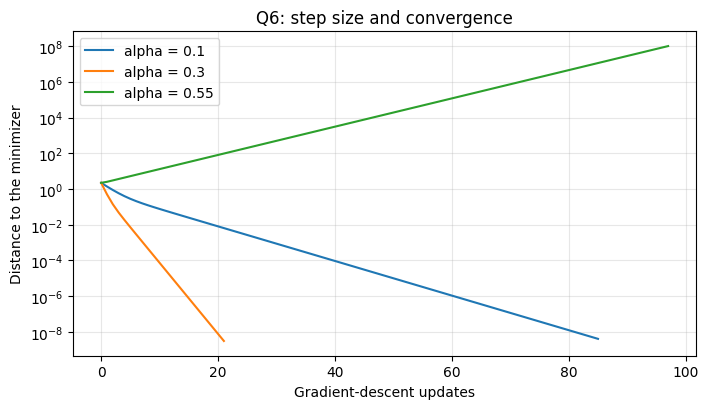

In [23]:
q6_results, q6_table, q6_fig = {}, None, None
if RUN_Q6:
    check_q6()
    H = np.array([[3., 1.], [1., 3.]])
    g = np.array([-5., -7.])
    x_reference = np.linalg.solve(H, -g)
    rows = []
    q6_fig, ax = plt.subplots(figsize=(7.2, 4.2))
    for alpha in (0.10, 0.30, 0.55):
        result = gradient_descent(H, g, np.zeros(2), alpha)
        q6_results[alpha] = result
        errors = np.linalg.norm(result["x"] - x_reference, axis=1)
        rows.append({"alpha": alpha, "updates": len(result["x"])-1,
                     "status": result["status"], "final_gradient_norm": result["grad_norm"][-1],
                     "final_error": errors[-1]})
        ax.semilogy(np.arange(len(errors)), np.maximum(errors, np.finfo(float).tiny), label=f"alpha = {alpha:g}")
    q6_table = pd.DataFrame(rows)
    display(q6_table)
    ax.set(xlabel="Gradient-descent updates", ylabel="Distance to the minimizer",
           title="Q6: step size and convergence")
    ax.grid(True, alpha=0.3)
    ax.legend()
    q6_fig.tight_layout()
    plt.show()
else:
    print("Q6 skipped. Complete Q6(a), then enable RUN_Q6.")


### Q6(c). Your interpretation

**TODO:** Give the signed factors and your explanation (at most 100 words).

The signed factor denotes the increasing ratio of error for each update.

If -1 < r  < 1 (r: signed factor), the run converges and otherwise diverges.

The convergence speed is generally faster if r is closer to 0.

Since alpha=0.3 has signed factors closer to 0 compared to alpha=0.1, its convergence speed is faster.

On the other hand, alpha=0.55 has a signed factor whose absolute value exceeds 1, thus diverges.

## Q7. L2-regularized logistic regression in PyTorch [30 points]

Use only `Train_Data.txt` and `Test_Data.txt`. Each row contains **one ID, nine predictors, and a class label**. The files contain 599 and 100 records, respectively. The nine predictors, in order, are Clump Thickness, Uniformity of Cell Size, Uniformity of Cell Shape, Marginal Adhesion, Single Epithelial Cell Size, Bare Nuclei, Bland Chromatin, Normal Nucleoli, and Mitoses. Exclude ID from the inputs; map class 2 to 0 (benign) and class 4 to 1 (malignant).

**Provided preprocessing.** The notebook keeps repeated IDs together in a fixed, seed-42 split: 476 fitting and 123 validation records. Missing values (`?`) are imputed with fitting-set medians. Features are standardized with fitting-set means and population standard deviations; zero standard deviations are replaced by one. The same fitted statistics transform validation data. Use this code unchanged and use all nine predictors; no feature engineering is required.

For standardized input $z_i$, the model returns the logit $s_i=w^Tz_i+b$. Train with
$$J_\lambda(w,b)=\frac1m\sum_{i=1}^{m}\left[\log(1+e^{s_i})-y_i s_i\right]
+\frac{\lambda}{2}\|w\|_2^2.$$
Use `BCEWithLogitsLoss(reduction="mean")` for the first term, with logits rather than sigmoid outputs. Penalize **weights only**, not the bias; use no optimizer weight decay. Predict malignant when $\sigma(s_i)\geq0.5$, equivalently $s_i\geq0$.


### Q7. Required implementation and experiments

**Fixed settings.** CPU, `float64`, zero-initialized weights and bias, full-batch SGD, learning rate 0.05, 2,000 updates, no momentum, and logging every 10 updates (including update 0). Keep these settings and the data split identical across runs. Only $\lambda$ varies.

**(a) [10 points]** Complete `LogisticRegression.forward`, `regularized_loss`, and `train_one_update`. The training loop and preprocessing are already supplied. Run the provided checks. Briefly explain why the model must return logits to the specified loss and why preprocessing is fitted only on the fitting subset.

**(b) [12 points]** Train exactly three models with $\lambda\in\{0,0.01,0.1\}$. Produce the supplied table of fitting accuracy, validation accuracy, validation BCE, and $\|w\|_2$, and one plot of fitting BCE against update for all three models. Select the **positive** $\lambda$ with the lowest validation BCE; break an exact tie by choosing the larger $\lambda$. Use unrounded values. The $\lambda=0$ model is the baseline; compare it with the selected L2 model, even if the baseline has better validation BCE. No additional parameter search is required.

**(c) [8 points]** Freeze the selection before opening `Test_Data.txt`. Enable the supplied final stage, which refits preprocessing on all 599 training records and retrains the baseline and selected L2 model from zero. Report full-training and test accuracy for these two models, then give the selected L2 model's test confusion matrix (rows = true class; columns = predicted class; order = benign, malignant) and its false-negative count. Do not retune after seeing test results.

**Discussion and report.** Include the three-row development table, one loss figure, the two-row final table, and one confusion matrix in your PDF. In a total of 100–150 words for Q7, answer (a), justify the selection in (b), and comment on regularization and the malignant cases missed in (c). The final-stage ID-overlap count is provided context: repeated IDs across the official files limit a patient-independent interpretation. This exercise does not establish clinical performance.

In [24]:
# PROVIDED: this reader is called on the test file ONLY in the final-stage cell.
def read_dataset(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. Put both text files next to the notebook or edit DATA_DIR.")
    frame = pd.read_csv(path, header=None, na_values=["?"], skip_blank_lines=True)
    if frame.shape[1] != 11:
        raise ValueError("Expected ID, nine predictors, and class (11 columns).")
    frame.columns = COLUMNS
    if frame[["ID", "class"]].isna().any().any():
        raise ValueError("ID and class cannot be missing.")
    if not set(frame["class"].unique()).issubset({2, 4}):
        raise ValueError("Expected class codes 2 and 4.")
    raw = frame[FEATURE_NAMES].to_numpy(dtype=np.float64)
    known = raw[np.isfinite(raw)]
    if np.isinf(raw).any() or (known.size and ((known < 1).any() or (known > 10).any())):
        raise ValueError("Observed predictors must lie between 1 and 10.")
    return frame


def fixed_group_split(frame):
    ids = np.random.default_rng(SEED).permutation(np.unique(frame["ID"].to_numpy()))
    n_val = int(np.ceil(0.20 * len(ids)))
    is_val = frame["ID"].isin(ids[:n_val]).to_numpy()
    fit_idx, val_idx = np.flatnonzero(~is_val), np.flatnonzero(is_val)
    assert set(frame.iloc[fit_idx]["ID"]).isdisjoint(frame.iloc[val_idx]["ID"])
    return fit_idx, val_idx


def fit_preprocessor(raw):
    raw = np.asarray(raw, dtype=np.float64)
    if raw.ndim != 2 or raw.shape[1] != 9 or np.isinf(raw).any():
        raise ValueError("Expected a finite-or-missing matrix with nine columns.")
    if np.isnan(raw).all(axis=0).any():
        raise ValueError("A fitting column is entirely missing.")
    medians = np.nanmedian(raw, axis=0)
    imputed = np.where(np.isnan(raw), medians, raw)
    means, scales = imputed.mean(axis=0), imputed.std(axis=0, ddof=0)
    scales = np.where(scales == 0, 1.0, scales)
    return {"medians": medians, "means": means, "scales": scales}


def transform_features(raw, state):
    raw = np.asarray(raw, dtype=np.float64)
    if raw.ndim != 2 or raw.shape[1] != len(state["medians"]):
        raise ValueError("Feature dimension does not match the fitted preprocessor.")
    transformed = (np.where(np.isnan(raw), state["medians"], raw) - state["means"]) / state["scales"]
    if not np.isfinite(transformed).all():
        raise ValueError("Transformed features must be finite.")
    return transformed


In [25]:
train_df = None
if RUN_Q7:
    train_df = read_dataset(DATA_DIR / "Train_Data.txt")
    assert train_df.shape == (599, 11), "Use the unmodified supplied training file."
    X_raw = train_df[FEATURE_NAMES].to_numpy(dtype=np.float64)
    y_all = (train_df["class"].to_numpy() == 4).astype(np.float64)
    fit_idx, val_idx = fixed_group_split(train_df)
    assert (len(fit_idx), len(val_idx)) == (476, 123)
    preprocessor = fit_preprocessor(X_raw[fit_idx])
    X_fit = transform_features(X_raw[fit_idx], preprocessor)
    X_val = transform_features(X_raw[val_idx], preprocessor)
    y_fit, y_val = y_all[fit_idx], y_all[val_idx]
    audit = pd.DataFrame([
        {"subset": name, "records": len(idx), "benign": int((y_all[idx] == 0).sum()),
         "malignant": int((y_all[idx] == 1).sum()), "missing_entries": int(np.isnan(X_raw[idx]).sum())}
        for name, idx in [("Fitting", fit_idx), ("Validation", val_idx)]])
    display(audit)
    np.testing.assert_allclose(X_fit.mean(axis=0), np.zeros(9), atol=1e-12)
    assert np.isfinite(X_fit).all() and np.isfinite(X_val).all()
    print("Preprocessing uses only fitting records. Test_Data.txt has not been opened.")
else:
    print("Q7 data preparation skipped. Enable RUN_Q7 after completing Q7(a).")


,subset,records,benign,malignant,missing_entries
0,Fitting,476,293,183,10
1,Validation,123,86,37,5


Preprocessing uses only fitting records. Test_Data.txt has not been opened.


In [27]:
class LogisticRegression(nn.Module):
    def __init__(self, n_features=9):
        super().__init__()
        self.linear = nn.Linear(n_features, 1, bias=True, dtype=DTYPE, device=DEVICE)
        nn.init.zeros_(self.linear.weight)
        nn.init.zeros_(self.linear.bias)

    def forward(self, X):
        """Return logits of shape (m,), not probabilities or shape (m,1)."""
        # TODO Q7(a): return one logit per sample.
        return self.linear(X).squeeze(-1)
        # raise NotImplementedError("Complete forward.")


def regularized_loss(logits, targets, model, lambda_):
    """Return mean BCE + lambda_/2 times the squared L2 norm of weights only."""
    # TODO Q7(a): do not regularize the bias.
    mean_BCE = LOSS(logits, targets)
    l2 = torch.sum(model.linear.weight ** 2)

    return mean_BCE + (lambda_ / 2) * l2
    # raise NotImplementedError("Complete regularized_loss.")


def train_one_update(model, optimizer, X, y, lambda_):
    """Perform one full-batch training update; return nothing.

    Clear old gradients, compute the objective, backpropagate, then update.
    The provided optimizer has no momentum and no weight decay.
    """
    # TODO Q7(a): clear gradients, evaluate the loss, backpropagate, and step.
    optimizer.zero_grad()
    loss = regularized_loss(model(X), y, model, lambda_)
    loss.backward()
    optimizer.step()
    # raise NotImplementedError("Complete train_one_update.")


In [28]:
# PROVIDED: full-batch training and evaluation.
def to_tensor(x):
    return torch.as_tensor(x, dtype=DTYPE, device=DEVICE)


def train_model(X, y, lambda_, X_validation=None, y_validation=None,
                lr=LR, updates=EPOCHS, log_every=LOG_EVERY):
    if (X_validation is None) != (y_validation is None):
        raise ValueError("Provide both validation inputs and targets, or neither.")
    if lambda_ < 0 or lr <= 0 or updates < 0 or log_every <= 0:
        raise ValueError("Invalid training setting.")
    X_t, y_t = to_tensor(X), to_tensor(y)
    X_v = to_tensor(X_validation) if X_validation is not None else None
    y_v = to_tensor(y_validation) if y_validation is not None else None
    model = LogisticRegression(X_t.shape[1])
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.0, weight_decay=0.0)
    history = []
    for k in range(updates + 1):
        if k % log_every == 0 or k == updates:
            with torch.no_grad():
                logits = model(X_t)
                history.append({"update": k, "fit_bce": float(LOSS(logits, y_t)),
                                "objective": float(regularized_loss(logits, y_t, model, lambda_)),
                                "val_bce": float(LOSS(model(X_v), y_v)) if X_v is not None else np.nan})
        if k < updates:
            train_one_update(model, optimizer, X_t, y_t, lambda_)
    return model, pd.DataFrame(history)


def model_scores(model, X, y):
    with torch.no_grad():
        logits = model(to_tensor(X))
        prediction = (logits >= 0).cpu().numpy().astype(int)
        truth = np.asarray(y, dtype=int)
        matrix = np.bincount(2 * truth + prediction, minlength=4).reshape(2, 2)
        return {"bce": float(LOSS(logits, to_tensor(y))),
                "accuracy_percent": 100.0 * float((prediction == truth).mean()),
                "weight_norm": float(torch.linalg.vector_norm(model.linear.weight)),
                "confusion": matrix, "prediction": prediction}


def select_positive_lambda(table):
    eligible = table[table["lambda"] > 0]
    if eligible.empty or not np.isfinite(eligible["validation_bce"]).all():
        raise ValueError("Need finite validation BCE for positive lambda candidates.")
    # Raw, unrounded BCE first. Exact ties go to the larger lambda.
    chosen = eligible.sort_values(["validation_bce", "lambda"],
                                 ascending=[True, False], kind="stable").iloc[0]
    return float(chosen["lambda"])


def check_q7():
    X = to_tensor([[1., -2.], [0.5, 1.], [-1., 2.]])
    y = to_tensor([1., 0., 1.])
    model = LogisticRegression(2)
    with torch.no_grad():
        model.linear.weight.copy_(to_tensor([[0.3, -0.2]]))
        model.linear.bias.fill_(0.4)
    logits = model(X)
    assert logits.shape == y.shape == (3,)
    np.testing.assert_allclose(logits.detach().numpy(), [1.1, 0.35, -0.3], atol=1e-12, rtol=0)
    lambda_ = 0.7
    loss = regularized_loss(logits, y, model, lambda_)
    expected = LOSS(logits, y) + 0.5 * lambda_ * (0.3**2 + 0.2**2)
    torch.testing.assert_close(loss, expected, rtol=0, atol=1e-12)
    model.zero_grad()
    loss.backward()
    residual = torch.sigmoid(logits.detach()) - y
    grad_w = X.T @ residual / len(y) + lambda_ * model.linear.weight.detach().squeeze(0)
    grad_b = residual.mean()
    torch.testing.assert_close(model.linear.weight.grad.squeeze(0), grad_w, rtol=0, atol=1e-12)
    torch.testing.assert_close(model.linear.bias.grad.squeeze(), grad_b, rtol=0, atol=1e-12)
    # Also verifies train_one_update clears any pre-existing gradients.
    before_w, before_b = model.linear.weight.detach().clone(), model.linear.bias.detach().clone()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.05, weight_decay=0, momentum=0)
    train_one_update(model, optimizer, X, y, lambda_)
    torch.testing.assert_close(model.linear.weight, before_w - 0.05*grad_w, rtol=0, atol=1e-12)
    torch.testing.assert_close(model.linear.bias, before_b - 0.05*grad_b, rtol=0, atol=1e-12)
    # The intercept must not enter the penalty, even at a nonzero value.
    z = LogisticRegression(2)
    with torch.no_grad():
        z.linear.bias.fill_(3.0)
    torch.testing.assert_close(regularized_loss(z(X), y, z, 9.0), LOSS(z(X), y), rtol=0, atol=1e-12)
    print("Q7 logits, squared-L2, bias-exclusion, gradient, and update checks passed.")


Q7 logits, squared-L2, bias-exclusion, gradient, and update checks passed.


,lambda,fitting_accuracy_percent,validation_accuracy_percent,validation_bce,weight_norm
0,0.00,96.008403,97.560976,0.088087,2.537146
1,0.01,96.218487,97.560976,0.088922,2.008275
2,0.10,95.798319,96.747967,0.130824,1.163776


Frozen positive lambda, selected using validation BCE: 0.01
Baseline lambda is 0. No test data were used in this selection.


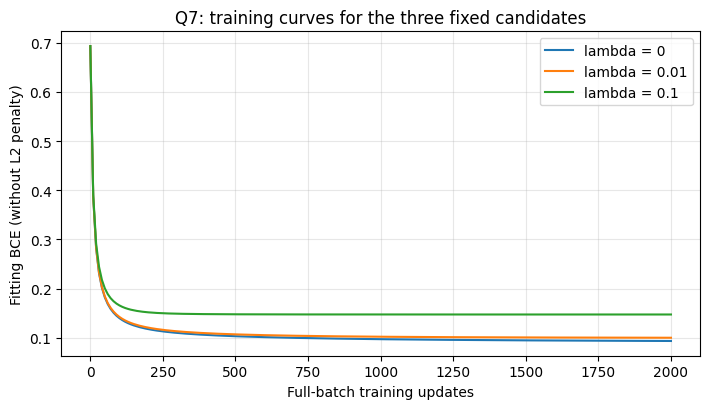

In [29]:
development_table, selected_lambda, q7_fig = None, None, None
development_models, development_histories = {}, {}
if RUN_Q7:
    check_q7()
    rows = []
    q7_fig, ax = plt.subplots(figsize=(7.2, 4.2))
    for lambda_ in LAMBDAS:
        model, history = train_model(X_fit, y_fit, lambda_, X_val, y_val)
        development_models[lambda_], development_histories[lambda_] = model, history
        fitting, validation = model_scores(model, X_fit, y_fit), model_scores(model, X_val, y_val)
        rows.append({"lambda": lambda_, "fitting_accuracy_percent": fitting["accuracy_percent"],
                     "validation_accuracy_percent": validation["accuracy_percent"],
                     "validation_bce": validation["bce"], "weight_norm": fitting["weight_norm"]})
        ax.plot(history["update"], history["fit_bce"], label=f"lambda = {lambda_:g}")
    development_table = pd.DataFrame(rows)
    display(development_table)
    selected_lambda = select_positive_lambda(development_table)
    print("Frozen positive lambda, selected using validation BCE:", selected_lambda)
    print("Baseline lambda is 0. No test data were used in this selection.")
    ax.set(xlabel="Full-batch training updates", ylabel="Fitting BCE (without L2 penalty)",
           title="Q7: training curves for the three fixed candidates")
    ax.grid(True, alpha=0.3)
    ax.legend()
    q7_fig.tight_layout()
    plt.show()
else:
    print("Q7 development skipped.")


### Selection checkpoint

Before enabling `RUN_FINAL_EVALUATION`, check the development table and record your selected positive lambda here: **0.01**. Do not change the model or training settings after reading the test results. The final cell refits both models from zero before opening the test file.

In [30]:
# PROVIDED: this is the ONLY cell that opens Test_Data.txt.
# In the starter, enable it only after checking the frozen selection above.
final_table, selected_confusion, shared_id_count = None, None, None
refitted_models = {}
if RUN_FINAL_EVALUATION:
    if not RUN_Q7 or selected_lambda is None or train_df is None:
        raise RuntimeError("Complete Q7 development and freeze the positive lambda first.")
    full_preprocessor = fit_preprocessor(X_raw)
    X_full = transform_features(X_raw, full_preprocessor)
    # Freeze two configurations, then train both WITHOUT reading the test file.
    frozen = [("Baseline", 0.0), ("Selected L2", selected_lambda)]
    for label, lambda_ in frozen:
        model, _ = train_model(X_full, y_all, lambda_)
        refitted_models[label] = model
    test_df = read_dataset(DATA_DIR / "Test_Data.txt")
    assert test_df.shape == (100, 11), "Use the unmodified supplied test file."
    X_test = transform_features(test_df[FEATURE_NAMES].to_numpy(dtype=np.float64), full_preprocessor)
    y_test = (test_df["class"].to_numpy() == 4).astype(np.float64)
    rows = []
    for label, lambda_ in frozen:
        model = refitted_models[label]
        train_scores = model_scores(model, X_full, y_all)
        test_scores = model_scores(model, X_test, y_test)
        rows.append({"model": label, "lambda": lambda_,
                     "full_training_accuracy_percent": train_scores["accuracy_percent"],
                     "test_accuracy_percent": test_scores["accuracy_percent"]})
        if label == "Selected L2":
            selected_confusion = test_scores["confusion"]
    final_table = pd.DataFrame(rows)
    display(final_table)
    display(pd.DataFrame(selected_confusion,
                        index=["True benign (0)", "True malignant (1)"],
                        columns=["Predicted benign (0)", "Predicted malignant (1)"]))
    print("Selected L2 false negatives:", int(selected_confusion[1, 0]))
    shared_id_count = len(set(train_df["ID"]) & set(test_df["ID"]))
    print("Distinct IDs appearing in BOTH supplied files:", shared_id_count)
    print("Keep this official split unchanged. Its accuracy is not a patient-independent clinical validation.")
else:
    print("Final test evaluation is disabled; freeze the validation choice before enabling it.")


,model,lambda,full_training_accuracy_percent,test_accuracy_percent
0,Baseline,0.00,96.327212,100.0
1,Selected L2,0.01,96.494157,100.0


,Predicted benign (0),Predicted malignant (1)
True benign (0),79,0
True malignant (1),0,21


Selected L2 false negatives: 0
Distinct IDs appearing in BOTH supplied files: 6
Keep this official split unchanged. Its accuracy is not a patient-independent clinical validation.


### Q7(a)–(c). Your discussion

**TODO:** Write 100–150 words total. Explain logits and fitting-only preprocessing, justify the chosen positive lambda, compare regularization results, and discuss false negatives. The supplied overlap count is context, not an extra experiment.
(a)
The model returns logits because the loss function(BCEWithLogitsLoss) implemented afterwards pre-computes the probability with the sigmoid function and thus requires logits as an input. The preprocessing fits only the fitting subset because the validation set cannot be used as a criterion for fitting, so as to prevent data leakage.
(b)
Selected lambda = 0.01: It is the parameter with the lowest validation BCE.
Compared with baseline: Although regularization reduces the weight norm, the baseline has a lower validation BCE, which means regularization failed to enhance the performance of validation for this experiment.
(c)
Both the baseline and L2 showed the same test accuracy, so the test set is not capable of distinguishing the effect of regularization. The models acheived 100% test accuracy with zero false negatives. However this result cannot be used to accurately evaluate the model, because the existence of ID-overlap clearly limits the evaluation quality of the test data.

In [31]:
# PROVIDED: final readiness check. No test-accuracy target is imposed.
if RUN_Q6 and RUN_Q7 and RUN_FINAL_EVALUATION:
    assert len(q6_table) == 3 and len(development_table) == 3 and len(final_table) == 2
    assert selected_confusion.shape == (2, 2) and selected_confusion.sum() == 100
    assert selected_lambda in (0.01, 0.1)
    assert all(len(development_histories[l]) == 201 for l in LAMBDAS)
    assert all(development_histories[l]["update"].iloc[-1] == 2000 for l in LAMBDAS)
    print("All required numerical tables and figures have been generated. Add the written discussion and save outputs.")
else:
    print("Starter runs safely before completion. Enable all sections only when ready; add your written responses.")


All required numerical tables and figures have been generated. Add the written discussion and save outputs.
